[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/05_module_rating_pressure_drop.ipynb)

# 5 · A fixed module: stage cut as an output, and bore pressure drop

So far the stage cut was specified and the area calculated (*design* mode). On a real plant the
module already exists, and the stage cut follows from the **feed flow** and the pressures
(*rating* mode). `rate_module()` solves that problem.

**Bore-side pressure drop.** With the feed on the shell side and the permeate inside fibre bores,
the permeate pressure rises towards the closed end of each fibre (Hagen–Poiseuille for a
compressible gas):

$$\frac{dp}{dx} = -\frac{128\,\mu\,R\,T\,q}{\pi\, d_i^4\, n_f\, p}$$

That eats into the pressure ratio exactly where the separation is hardest. Narrow or long fibres
make it worse.

For counter-current flow the solver iterates between the shooting solution and the bore-pressure
profile, which integrates in closed form once the permeate flow profile is known:
$p(z)^2 = p_{out}^2 + 2K\int_0^z \mu\,q\,dz'$.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


## Size a module, then vary the feed flow

In [2]:
m = Membrane(MEMBRANE_PRESETS["Polyimide CO2/CH4, a=35 (Makaruk 2010)"])
xf = FEED_PRESETS["biogas, 60% CH4 (Makaruk 2010)"]
F_design = nm3h_to_mols(100)
design = countercurrent(m, xf, 0.40, 15, 1, F_design, profile=False)
module = HollowFibreModule.for_area(design.area, length=1.0, d_inner=150e-6, d_outer=300e-6)
print(module)

HollowFibreModule(area=54.3 m2, n_fibres=5.761e+04, L=1 m, d_i=150 um, d_o=300 um)


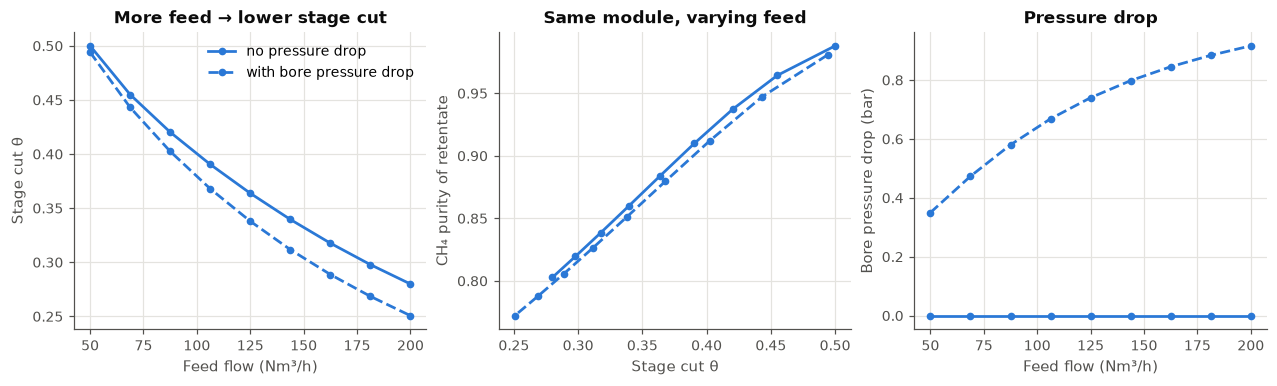

,feed_Nm3h,pressure_drop,theta,CH4_purity,CH4_recovery,bore_dp_bar
0,50.00,False,0.5000,0.9880,0.8233,0.0000
1,50.00,True,0.4941,0.9807,0.8269,0.3500
2,68.75,False,0.4550,0.9643,0.8760,0.0000
3,68.75,True,0.4431,0.9472,0.8792,0.4735
4,87.50,False,0.4203,0.9373,0.9056,0.0000
5,87.50,True,0.4025,0.9121,0.9083,0.5803
6,106.25,False,0.3905,0.9100,0.9244,0.0000
7,106.25,True,0.3679,0.8797,0.9267,0.6686
8,125.00,False,0.3638,0.8840,0.9373,0.0000
9,125.00,True,0.3379,0.8512,0.9392,0.7402


In [3]:
flows = F_design * np.linspace(0.5, 2.0, 9)
rows = []
for F in flows:
    for dp in (False, True):
        r = rate_module(m, xf, F, 15, 1, module, "countercurrent", pressure_drop=dp, profile=False)
        rows.append(dict(feed_Nm3h=mols_to_nm3h(F), pressure_drop=dp, theta=r.theta,
                         CH4_purity=r.x_ret[1], CH4_recovery=r.recovery("CH4", "retentate"),
                         bore_dp_bar=r.extra["bore_dp_bar"]))
rt = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.4), constrained_layout=True)
for dp, ls, lab in [(False, "-", "no pressure drop"), (True, "--", "with bore pressure drop")]:
    s = rt[rt["pressure_drop"] == dp]
    ax[0].plot(s["feed_Nm3h"], s["theta"], color=COLORS["countercurrent"], ls=ls, marker="o", ms=4, label=lab)
    ax[1].plot(s["theta"], s["CH4_purity"], color=COLORS["countercurrent"], ls=ls, marker="o", ms=4, label=lab)
    ax[2].plot(s["feed_Nm3h"], s["bore_dp_bar"], color=COLORS["countercurrent"], ls=ls, marker="o", ms=4, label=lab)
ax[0].set(xlabel="Feed flow (Nm³/h)", ylabel="Stage cut θ", title="More feed → lower stage cut")
ax[1].set(xlabel="Stage cut θ", ylabel="CH₄ purity of retentate", title="Same module, varying feed")
ax[2].set(xlabel="Feed flow (Nm³/h)", ylabel="Bore pressure drop (bar)", title="Pressure drop")
ax[0].legend(); plt.show()
rt.round(4)

## Interactive: fibre bore diameter and length

In [4]:
def explore(d_inner_um=150, length_m=1.0, feed_Nm3h=100.0, pattern="countercurrent"):
    mod = HollowFibreModule.for_area(design.area, length=length_m, d_inner=d_inner_um * 1e-6,
                                     d_outer=2 * d_inner_um * 1e-6)
    F = nm3h_to_mols(feed_Nm3h)
    ideal = rate_module(m, xf, F, 15, 1, mod, pattern, pressure_drop=False)
    real = rate_module(m, xf, F, 15, 1, mod, pattern, pressure_drop=True)
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4), constrained_layout=True)
    ax[0].plot(real.profile["area_fraction"], real.profile["p_perm_bar"], color=COLORS[pattern])
    ax[0].set(xlabel="Fraction of fibre length from the feed inlet", ylabel="Bore pressure (bar)",
              title="Permeate pressure along the fibre"); ax[0].set_ylim(bottom=0)
    i = m.components.index("CO2")
    for r, ls, lab in [(ideal, "-", "ideal"), (real, "--", "with pressure drop")]:
        ax[1].plot(r.profile["area_fraction"], r.profile["x"][i], color=COLORS[pattern], ls=ls, label=lab)
    ax[1].set(xlabel="Fraction of fibre length from the feed inlet", ylabel="CO₂ in feed side",
              title="Feed-side CO₂"); ax[1].legend(); plt.show()
    display(pd.DataFrame({"ideal": [ideal.theta, ideal.x_ret[1], 0.0],
                          "with pressure drop": [real.theta, real.x_ret[1], real.extra["bore_dp_bar"]]},
                         index=["stage cut", "CH4 purity (retentate)", "bore Δp (bar)"]).round(4))
    print(mod)

w.interact_manual(explore,
                  d_inner_um=w.IntSlider(value=150, min=60, max=600, step=10, description="bore (µm)"),
                  length_m=w.FloatSlider(value=1.0, min=0.3, max=3.0, step=0.1, description="length (m)"),
                  feed_Nm3h=w.FloatSlider(value=100, min=40, max=250, step=5, description="feed Nm³/h"),
                  pattern=w.Dropdown(options=["countercurrent", "cocurrent"]));

interactive(children=(IntSlider(value=150, description='bore (µm)', max=600, min=60, step=10), FloatSlider(val…

**Takeaway.** Stage cut is not set directly on a plant: it follows from feed flow, pressures and
module geometry. Bore pressure drop lowers the effective pressure ratio, which reduces both the
stage cut and the separation, most of all for narrow, long fibres.